# E75: Can Qwen3-1.7B's clean-model table fail a bad placement, and does RL read as the fine-tunes?

## The answer

Not yet: the clean-model table has not been shown to fail a bad placement of the right size. It fails a random change, but only one scaled 18 to 100 times beyond the update's size. The in-span part beats a random slice of its own size by under one percent of the ruler, and the plain rescaled update beats it on two of five updates. RL at step 100 reads mostly as the fine-tunes do; RL at step 10 leaves their range on all four rows with a filed range.

The shuffled-reward arm is still running and the arm trained on its own correct samples comes later, so nothing here says RL's update is learning. That null also gained 5.6 points of accuracy, with the cause not established. A later amendment updates this notebook when those arms land.


## What we were trying to test

The first deliverable is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. The second is the same table for fine-tuning and RL updates. The user chose the clean-model table as that test. This is its first full run.

**The table.** Each matrix is $W_0 = U V^\top + \Delta$. An update $\delta W$ changes the weights. A state is $W_0$ plus some part of $\delta W$, run with no masks. Its score is $K = \mathrm{KL}(\text{updated model} \,\|\, \text{state})$ over every position. The updated model is $W_0 + \delta W$ and reads 0. The original model $W_0$ reads the ruler, and every figure divides by that ruler. Γ plays no role in this table, so it reads weights and outputs, not VPD's faithfulness checks.

**The updates.** Three saved fine-tunes: the first fine-tune at step 10, the gold fine-tune at step 100, and the template fine-tune at step 100. Two come from RL's GRPO run, at steps 100 and 10. The template fine-tune reads its own 64 rows; the other four read 128 maths rows of 256 tokens. RL trained on its own samples and not on this text.

**The states, and what each rules out.**

- *In-span part:* the part of the least-squares split inside the subcomponents. This is the candidate.
- *Remainder:* what that split sends to Δ.
- *Often-on and rarely-on halves:* the update placed on the half of subcomponents Γ often or rarely switches on.
- *Adjoint split's change:* a different placement of the same update.
- *Random change:* rules out credit for any change. Its scale is searched until it moves $W_0$ as far as the update does.
- *Rescaled update:* $W_0 + t\,\delta W$, with $t$ the part's input-weighted norm over the update's. It tests whether size alone explains a part's score.
- *Random slice:* per matrix, $c\,Q Q^\top \delta W$, with $Q$ a random orthonormal basis on the output side and $c$ the scalar that matches the part's input-weighted energy exactly. A slice is still a part of the update, and on average it is the update shrunk, plus noise. It is not a wrong direction.

**The masked read.** Under $W_0$'s masks with Δ off, we add the whole update unmasked and ask what share of its clean KL reaches the output. That share is $\tau$. A value of 1 reads as in the clean model and 0 means nothing arrives.

**The control ran first.** The first fine-tune went through this code alone and had to reproduce stored numbers before anything else ran.


In [1]:
from pathlib import Path

from IPython.display import Image, Markdown, display

from commute.jobs import load_experiment

plot = load_experiment("qwen_rl_reads", "plot")
rules = load_experiment("qwen_rl_reads", "rules")
# score.json keeps only the updates of the job that last wrote it, so the table is rescored from the reads with the filed rules.
SCORE = plot.rescore(rules)
NAMES = [u for u, *_ in plot.UPDATES]


def show(name):
    display(Image(filename=str(Path(plot.FIG) / name), width=760))


def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


## What we expected, and why

We filed medium leans for RL only, from the fine-tunes' earlier reads. The whole update should barely reach the output under $W_0$'s masks. A random change should read at least ten times further from the updated model than the larger half. The in-span part should read below the remainder.

We filed no lean on whether the in-span part beats its random slice. An earlier review had pointed out that the table had no reference of the same size, so this was a real question. We also expected the gain to be unreadable on RL, since RL does not train on these rows.


## What we observed

### Which states does the table fail?


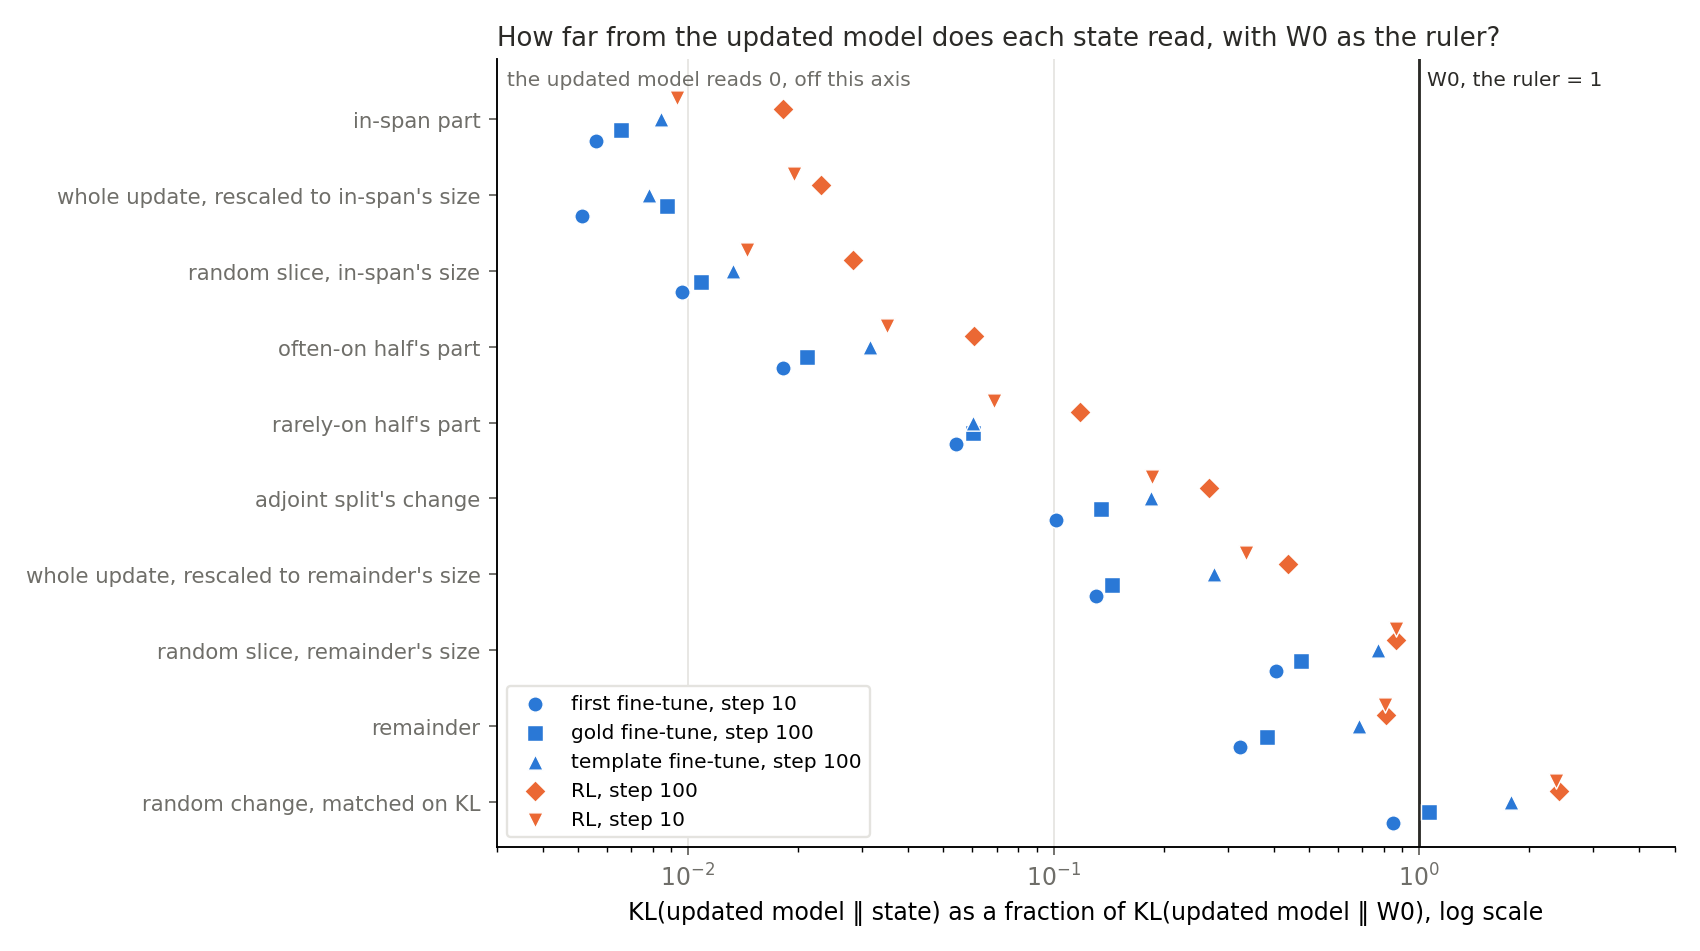

In [2]:
show("k_fraction.png")


**Reading it.** The table fails the random change and little else that is near the update's size. Random reads between 0.85 and 2.4 of the ruler on all five updates, but its scale is 18 to 100 times the size matched to the update. The candidates form one ladder on every update, with the in-span part lowest and the remainder near the top. RL sits to the right of the fine-tunes on every row, so each part leaves more of RL's distance uncovered. At the size matched to the update, the search's first step moved $W_0$ by under half a percent of the target. So a random change of the right size would probably read close to the ruler, but the table did not read one.


### Does the in-span part beat a state of its size that is not placed?


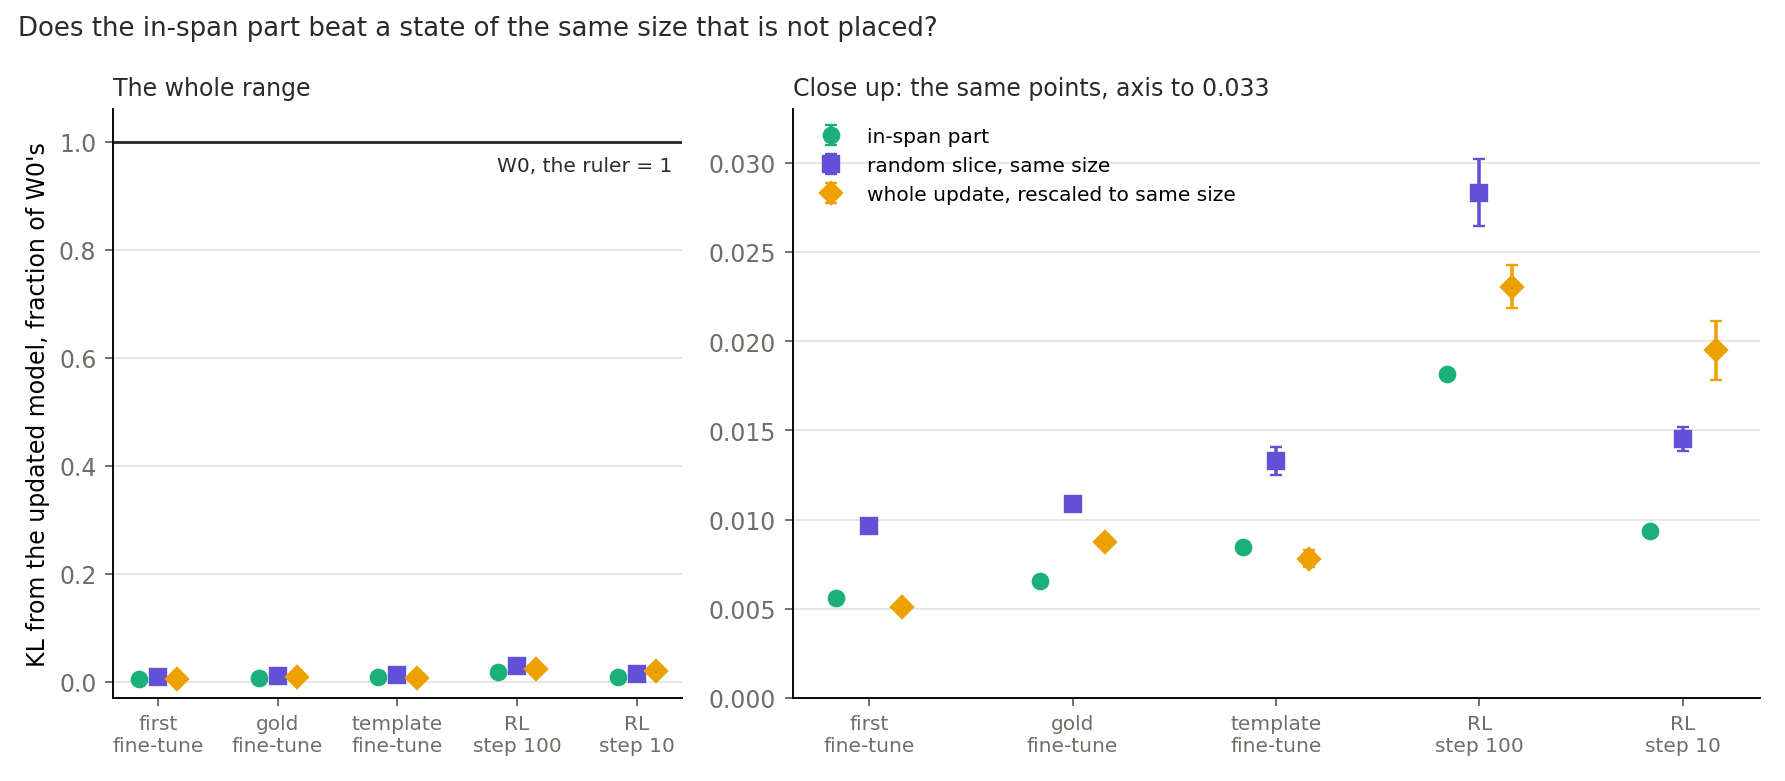

In [3]:
show("beats_size.png")


**Reading it.** By the filed rule yes, on all five updates, and the margin is small. On the first fine-tune the in-span part reads 0.009 nats and its slice 0.016, against the ruler's 1.635. The left panel shows how little that is. The gap is 0.4 to 1.0 percent of the ruler, and many times the row bootstrap's half-width, drawn as the bars. The rescaled update has no placement at all, and it read closer than the in-span part on the first and template fine-tunes, the second only just past its half-width. So no state here has been both the right size and wrong. A slice is part of the update, and in 82 of the 196 matrices the remainder is zero to rounding, so slice, in-span part and update are the same weights there.


### Does RL's update read as the fine-tunes do?


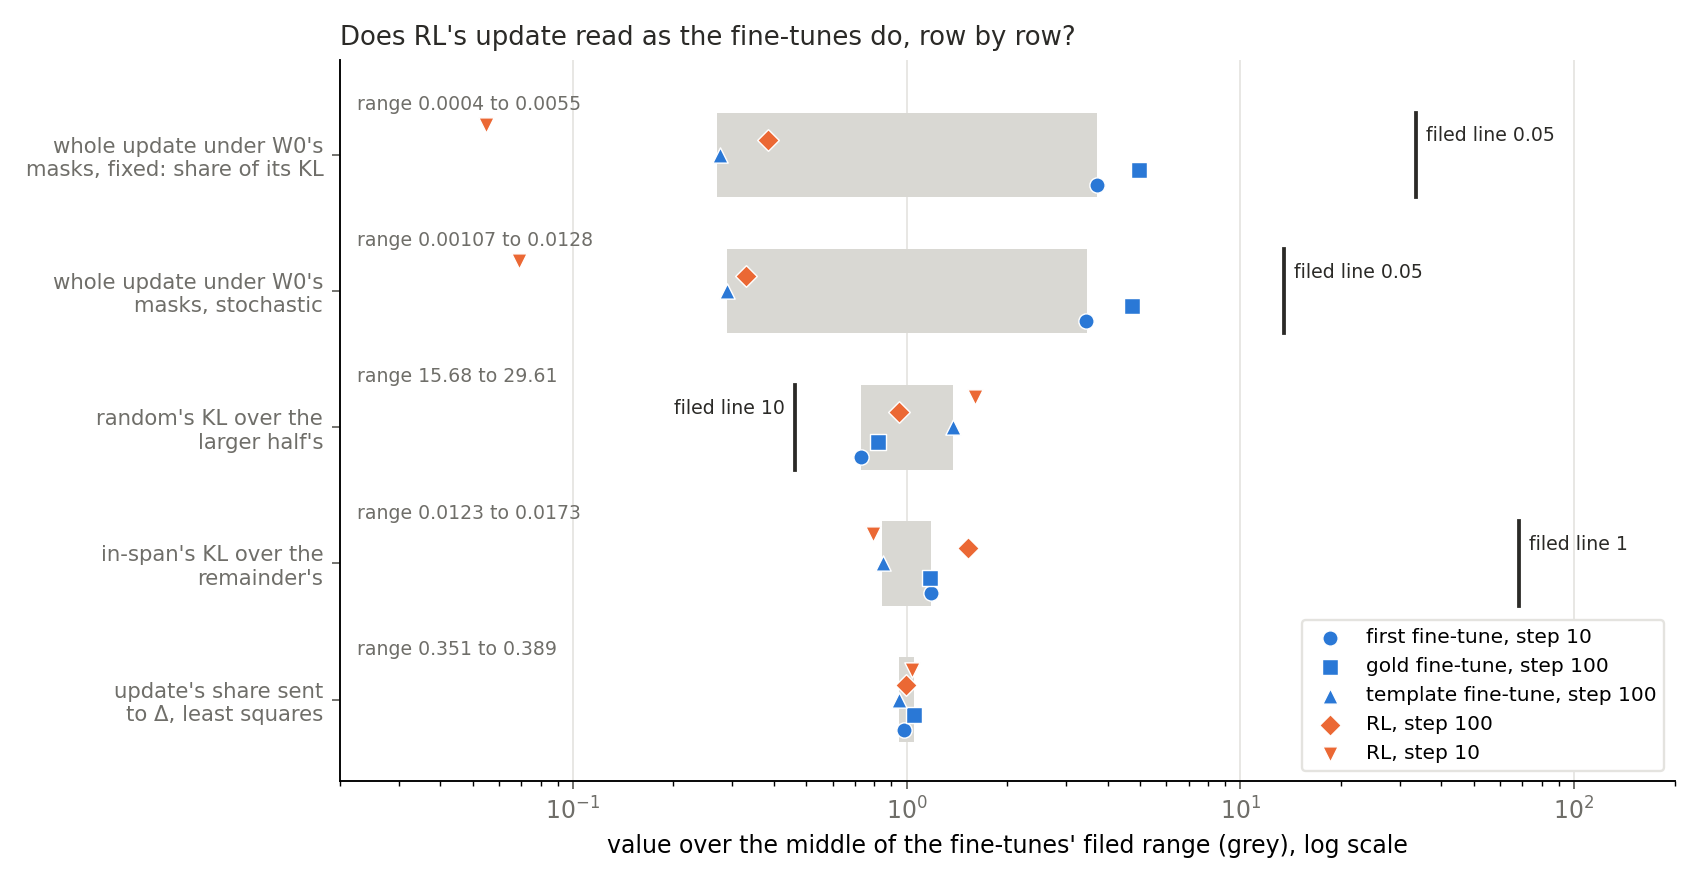

In [4]:
show("against_sft.png")


**Reading it.** RL at step 100 mostly does, and RL at step 10 mostly does not, though no filed label changed. All four filed labels came out as leaned on both RL updates. At step 100 only the in-span over remainder ratio leaves the grey range, at 0.022 against a top of 0.017. At step 10 all four rule rows leave it, the two masked shares falling four to five times below. The range is thin evidence. It comes from three updates, or two on the masked rows, and the gold fine-tune falls outside those two as well. RL's masked read at step 10 is 1.6e-6 nats, near where we have no measured floor. The share sent to Δ is inside the range on every update.


### Why is the gain unscored on RL, and how small is RL's ruler?


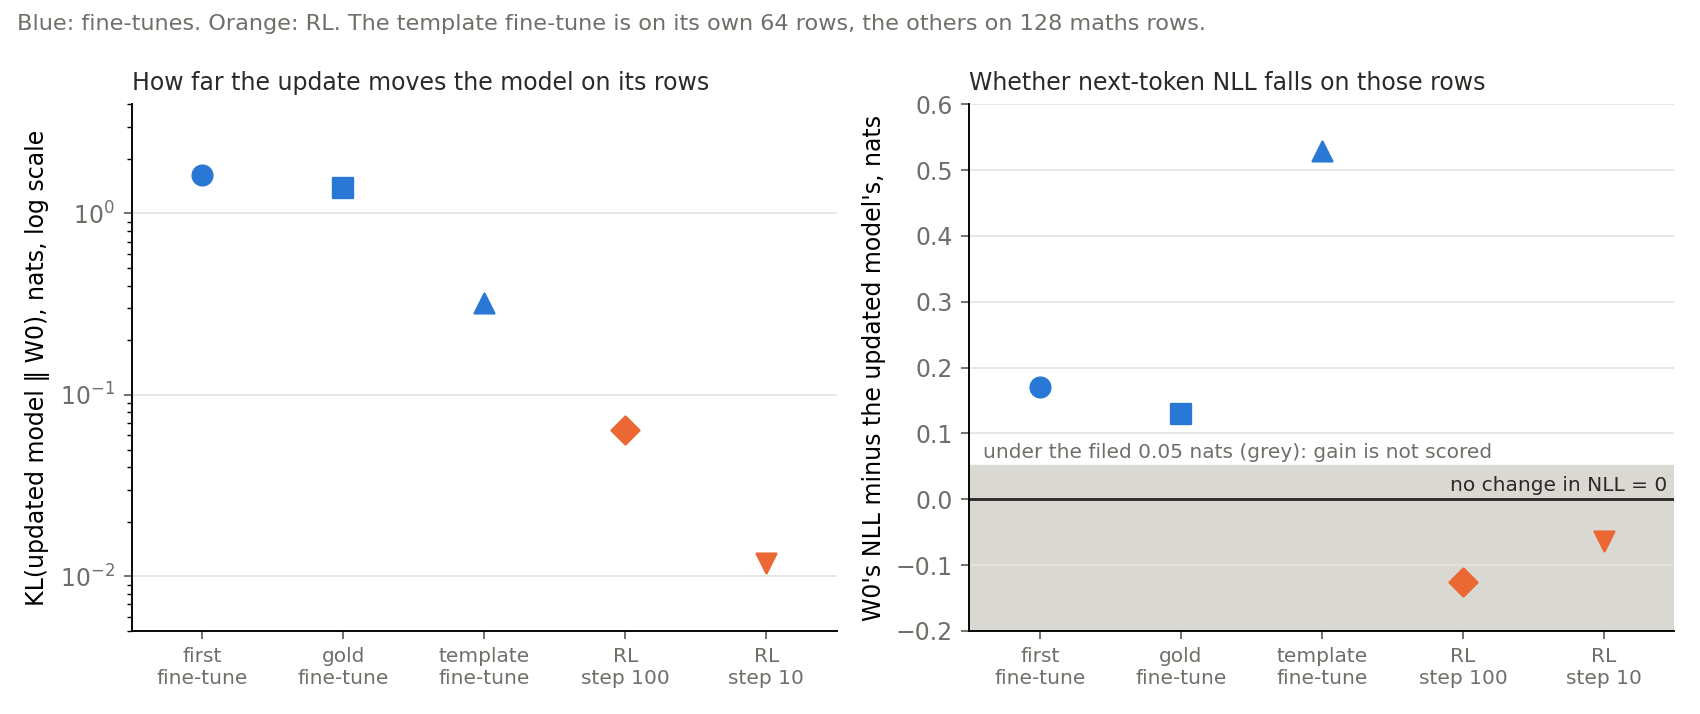

In [5]:
show("ruler.png")


**Reading it.** The gain cannot be read on RL because RL's update raises next-token NLL on these rows. The filed rule needs NLL to fall by at least 0.05 nats, and it rises by 0.125 at step 100 and 0.063 at step 10. So a "gain" there divides by a negative number and means nothing as a share of a drop, and the label reads unscored. RL's ruler is also much smaller on these rows, at 0.064 nats at step 100 against 1.6 on the first fine-tune. RL's update lowers the entropy of the output here, where all three fine-tunes raise it. These rows are maths text RL did not train on, so this says nothing about RL's accuracy on its own task.


## What we learned

The clean-model table separates large from small and real from random, and it barely separates placements. A size-matched reference now exists, and the filed rule reads "beats size" on all five updates, but only by under one percent of the ruler. For the first deliverable this means the test does not yet do its stated job: failing a bad placement of the right size is still unshown. For the second, the table's rows on RL have the same order as the fine-tunes', with RL's parts leaving more of a much smaller distance uncovered.

Under the original model's masks, with Δ off, the whole update reaches the output weakly on all five updates. How much the masked output depends on its tokens is not measured here.

## How compelling is the evidence

- **Control.** The first fine-tune reproduced every stored number with a gap of 0, and $W_0$'s own numbers matched on the other maths-row updates.
- **Coverage.** Five updates, two RL steps, one slice seed, one random draw, one stochastic draw per row. Masked reads use 32 rows. "All five" means these five.
- **Blind spots.** $K$ is not accuracy or gain. The table reads no masks and no Γ. A slice is random on the output side only.
- **Noise.** The bootstrap's half-width covers rows only. Slice seeds were not varied, so the gap's real noise is larger than the bars.
- **RL is not set against its null.** Shuffled rewards also gained accuracy, by the RL lead's note, cause not established.

## Surprises

No filed lean reversed.

- The plan expected the in-span part's norm share near 0.93 and read 0.83 to 0.87. The old figure is $\sqrt{1 - \text{remainder's share}}$, which assumes the two parts do not overlap under the input weighting, and they do. So the earlier estimate of the rescaled in-span state, three to five times below the in-span part, does not hold.
- The rescaled update beat the in-span part on two fine-tunes.
- On RL, the rescaled update reads close to the square law $(1-t)^2$ of the ruler. On the fine-tunes it reads well below that law.
- RL raises next-token NLL on these rows and lowers entropy. We expected a small or negative gain, but not this difference in entropy.

## What next

1. **The shuffled-reward and own-samples arms through this table.** Job 50755 is reading the first now. If the null reads as RL does, the differences above are not about reward.
2. **A state that is the right size and wrong.** A filed line for the table needs it, for example another update's change rescaled to this one's size. If it reads near the in-span part, the table cannot fail a placement. This is a new measurement and goes through `/design`.
3. **A noise floor for the table.** More slice seeds would say whether a margin under one percent is stable.

## Scorecard


In [6]:
def cell(u, row, digits=3):
    r = SCORE[u]["rows"][row]
    return f"{r['value']:.{digits}g} {r['read']}, {r['against_sft']}"


rows = [["control", "first fine-tune reproduces stored reads", "within 1e-3 relative", "gap 0", "passed"]]
rows.append(["transmission, fixed", "whole update barely reaches output", "at most 0.05 'deaf', at least 0.25 'carries'",
             "; ".join(f"{u} {cell(u, 'transmission_fixed')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["transmission, stochastic", "same under stochastic masks", "same", "; ".join(f"{u} {cell(u, 'transmission_stochastic')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["random_vs_halves", "random at least ten times the larger half", "ratio at least 10", "; ".join(f"{u} {cell(u, 'random_vs_halves')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["inspan_vs_remainder", "in-span below remainder", "ratio below 1", "; ".join(f"{u} {cell(u, 'inspan_vs_remainder')}" for u in NAMES), "as leaned on R100, R10"])
rows.append(["placement_vs_size", "in-span beats its slice", "gap above the bootstrap half-width", "; ".join(f"{u} {SCORE[u]['size']['gap_inspan']:.3g} ± {SCORE[u]['size']['width_inspan']:.2g}" for u in NAMES), "beats size on all; no lean filed"])
rows.append(["T2 label", "E72's gain label, no lean", "unscored under 0.05 nats", "; ".join(f"{u} {SCORE[u]['clean']['T2']}" for u in NAMES), "reported"])
table(["id", "claim", "rule", "read", "verdict"], rows)


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| control | first fine-tune reproduces stored reads | within 1e-3 relative | gap 0 | passed |
| transmission, fixed | whole update barely reaches output | at most 0.05 'deaf', at least 0.25 'carries' | u1 0.0055 deaf, inside; u2 0.00739 deaf, outside; u3 0.00041 deaf, inside; R100 0.000571 deaf, inside; R10 8.12e-05 deaf, outside | as leaned on R100, R10 |
| transmission, stochastic | same under stochastic masks | same | u1 0.0128 deaf, inside; u2 0.0175 deaf, outside; u3 0.00107 deaf, inside; R100 0.00122 deaf, inside; R10 0.000255 deaf, outside | as leaned on R100, R10 |
| random_vs_halves | random at least ten times the larger half | ratio at least 10 | u1 15.7 holds, inside; u2 17.7 holds, inside; u3 29.6 holds, inside; R100 20.4 holds, inside; R10 34.5 holds, outside | as leaned on R100, R10 |
| inspan_vs_remainder | in-span below remainder | ratio below 1 | u1 0.0173 holds, inside; u2 0.0171 holds, inside; u3 0.0124 holds, inside; R100 0.0223 holds, outside; R10 0.0116 holds, outside | as leaned on R100, R10 |
| placement_vs_size | in-span beats its slice | gap above the bootstrap half-width | u1 0.0066 ± 0.00033; u2 0.00596 ± 0.00043; u3 0.00156 ± 0.00025; R100 0.000654 ± 0.00012; R10 6.13e-05 ± 7.9e-06 | beats size on all; no lean filed |
| T2 label | E72's gain label, no lean | unscored under 0.05 nats | u1 carried; u2 carried; u3 carried; R100 unscored; R10 unscored | reported |

Here u1, u2 and u3 are the first, gold and template fine-tunes, and R100 and R10 are RL at steps 100 and 10. "inside" or "outside" compares a value with the range filed from the fine-tunes; u1 and u3 set most of those range ends, so they read inside by construction.

## Departures from the literature

Against VPD and `param-decomp`.

- The clean table is ours and is not one of VPD's checks. VPD judges a decomposition under stochastic, adversarial and CI-masked reconstruction; this table has no masks.
- The masked read uses $W_0$'s masks with Δ off and adds the update unmasked, as in the earlier transmission experiment. The library's Δ share and adversarial sources are not used.
- The stochastic masks use one draw per row at one seed, where the library draws afresh.
- RL's update comes from GRPO with the RL lead's recipe, and its departures are in that plan.

## Not run

1. The shuffled-reward arm, running now as job 50755, and the own-samples arm, later. No RL row is set against its null yet.
2. A state that is the right size and in a wrong direction.
3. A random change at the size matched to the update, on the table itself.
4. More than one slice seed, and any noise floor for $K$ below 1e-6.
5. Masked reads under the updated model's masks, block-level reads and the last matrix's positive control on RL.
6. Any adversary, and accuracy of any part.
7. RL at other steps.

Provenance: job 50596, one cluster L40, `normal` QoS, about 3.4 hours, $0. Results in `experiments/qwen_rl_reads/results/`; full tables in `reports/analyses/2026-11-03_analysis_e75-rl-reads.md`.
